Part 1: What features are

A feature is an input the model learns from. Right now our features are raw sensor readings, one number per sensor per cycle. Day 2 showed two problems with that:

Noise. A single reading jitters randomly. One cycle’s temperature might be high just by chance, so the model can mistake noise for wear.
No memory. A single row only knows “now.” But wear is about change over time: is this engine’s temperature rising? Is it getting more erratic? One reading can’t tell you that.

Feature engineering fixes this by computing new columns that summarize the recent history of each sensor.

The two rules of production features

These rules are what separate MLOps feature engineering from notebook feature engineering.

Rule 1: Only use the past. When the deployed model predicts for an engine at cycle 150, it has cycles 1 to 150. It does not have cycle 151. So every feature must be computable from current and earlier data only. A feature that peeks at the future works beautifully in training and is impossible in production. That’s leakage again, through time this time.

Rule 2: One function, used everywhere. The exact same code must compute features for training, validation, the test set and the live API. If training computes a “10-cycle average” one way and the API another way, the model gets inputs it never learned from. That’s training/serving skew, and it’s why features go into the package as a function, not live in a notebook.

Part 2: Rolling windows from scratch
The idea

A rolling mean (or moving average) replaces each value with the average of the last N values. Think of a window of fixed size sliding down the column one row at a time.

Here’s a tiny example with a window of 3:

row  value   window covers     rolling mean
 0     5     [5]               5.0
 1     7     [5, 7]            6.0
 2     6     [5, 7, 6]         6.0
 3     8     [7, 6, 8]         7.0
 4    10     [6, 8, 10]        8.0

Notice two things:

The window covers the current row and the rows before it, never rows after. That’s Rule 1, built in.
Rows 0 and 1 don’t have 3 values available yet. By default pandas would give NaN there. min_periods=1 means “average whatever’s available, even if it’s fewer than 3.” So row 0 is just 5 and row 1 is the average of 5 and 7.

Averaging smooths out random jitter: a single high reading gets diluted by its neighbours, while a real trend survives, because all the values in the window are rising together.

In [1]:
import sys
sys.path.append("..")

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from turbofan.data import load_cmapss, add_rul, split_by_engine

In [2]:
train = load_cmapss(Path("../data/raw/train_FD001.txt"))
train = add_rul(train)

In [3]:
s = pd.Series([5, 7, 6, 8, 10])
print(s.rolling(window=3).mean()) # the first two rows are returned as NaN since there aren't 3 els
print(s.rolling(window=3, min_periods=1).mean()) # average whatever’s available, even if it’s fewer than 3

0    NaN
1    NaN
2    6.0
3    7.0
4    8.0
dtype: float64
0    5.0
1    6.0
2    6.0
3    7.0
4    8.0
dtype: float64


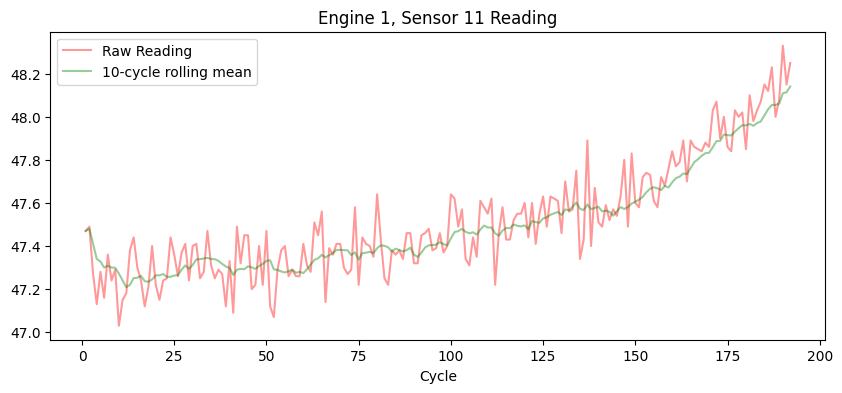

In [4]:
engine1 = train[train["unit"] == 1]

raw = engine1["sensor_11"]
smooth = raw.rolling(window=10, min_periods=1).mean()

plt.figure(figsize=(10, 4))
plt.plot(engine1["cycle"], raw, alpha=0.4, c='r', label='Raw Reading')
plt.plot(engine1["cycle"], smooth, alpha=0.4, c='g', label='10-cycle rolling mean')
plt.xlabel("Cycle")
plt.title("Engine 1, Sensor 11 Reading")
plt.legend()
plt.show()

# Rolling STD

In [5]:
s = pd.Series([5, 7, 6, 8, 10])
print(s.rolling(window=3, min_periods=1).std())

0         NaN
1    1.414214
2    1.000000
3    1.000000
4    2.000000
dtype: float64


In [6]:
# Rolling must be per engine
train["sensor_11_mean"] = train.groupby("unit")["sensor_11"].transform(lambda s: s.rolling(
    window=10, min_periods=1).mean(
))

In [7]:
print(train[train["unit"] == 2][["unit", "cycle", "sensor_11", "sensor_11_mean"]].head(3))

     unit  cycle  sensor_11  sensor_11_mean
192     2      1      46.93          46.930
193     2      2      47.24          47.085
194     2      3      47.22          47.130


Capping RUL

In [8]:
clip_rul = pd.Series([150, 130, 340, 33, 56, 66])
clip_rul.clip(upper=120)

0    120
1    120
2    120
3     33
4     56
5     66
dtype: int64

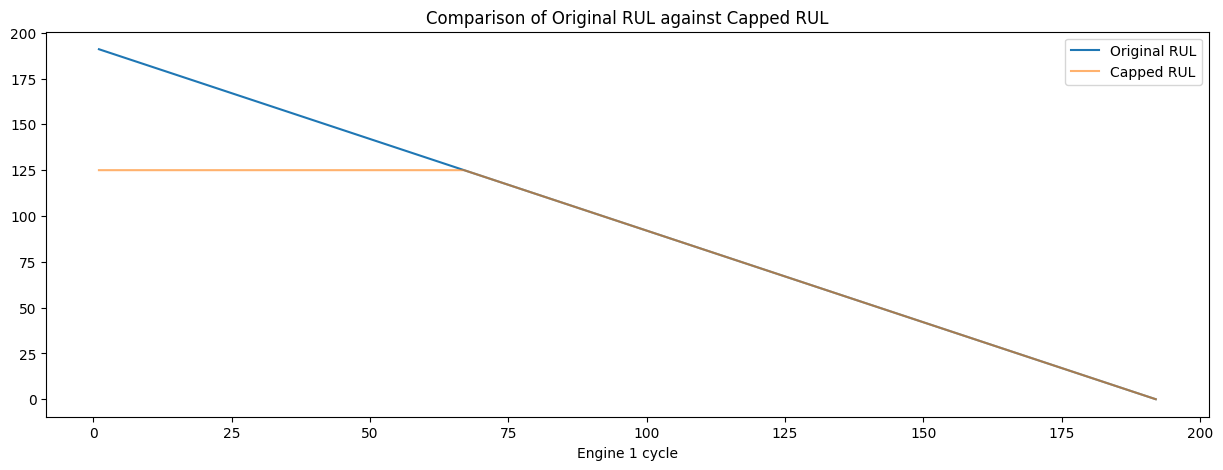

In [9]:
capped_rul = engine1["rul"].clip(upper=125)

plt.figure(figsize=(15, 5))
plt.plot(engine1["cycle"], engine1["rul"], label="Original RUL")
plt.plot(engine1["cycle"], capped_rul, label="Capped RUL", alpha=0.6)
plt.xlabel("Engine 1 cycle")
plt.title("Comparison of Original RUL against Capped RUL")
plt.legend()
plt.show()

Checking if the features module actually work

In [12]:
from turbofan.features import cap_rul, add_rolling_features, get_feature_columns

df = add_rolling_features(cap_rul(train))
features = get_feature_columns()

print(len(features))
print(df[features].isna().sum().sum(), "missing values")
print(df["rul"].max(), "= max RUL after capping")

45
0 missing values
125 = max RUL after capping


In [17]:
# Evaluating whether feature engineering helped

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import root_mean_squared_error
from turbofan.data import split_by_engine
from turbofan.features import FEATURE_SENSORS

tr, val = split_by_engine(df)

def evaluate(columns):
    model = RandomForestRegressor(n_estimators=100, random_state=41, n_jobs=-1)
    model.fit(tr[columns], tr["rul"])
    return root_mean_squared_error(val["rul"], model.predict(val[columns]))

rmse_raw = evaluate(FEATURE_SENSORS)
rmse_eng = evaluate(get_feature_columns())

print(f"Raw sensors only (15):        RMSE = {rmse_raw:.1f}")
print(f"Engineered features (45):     RMSE = {rmse_eng:.1f}")



Raw sensors only (15):        RMSE = 17.3
Engineered features (45):     RMSE = 16.6
